In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [28]:
x = pd.read_csv('https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML1.1%20linear%20regression/data/x.csv', index_col=0)['0']
y = pd.read_csv('https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML1.1%20linear%20regression/data/y.csv', index_col=0)['0']

In [29]:
x

0     1.462108
1     1.133769
2    -2.301539
3     1.744812
4     0.042214
5    -0.611756
6     0.319039
7    -0.761207
8     0.582815
9    -1.099891
10    0.865408
11    1.624345
12   -0.528172
13   -0.249370
14   -1.072969
15   -0.384054
16   -0.172428
17   -0.322417
18   -2.060141
19   -0.877858
Name: 0, dtype: float64

In [30]:
y

0     101.159902
1      78.442913
2    -159.238195
3     120.719533
4       2.920673
5     -42.326026
6      22.073585
7     -52.666163
8      40.323651
9     -76.098960
10     59.875573
11    112.384738
12    -36.542995
13    -17.253366
14    -74.236243
15    -26.571842
16    -11.929913
17    -22.307308
18   -142.536421
19    -60.737015
Name: 0, dtype: float64

In [36]:
class Model(object):
    def __init__(self, init_b0=0, init_b1=0):
        self.b0 = init_b0
        self.b1 = init_b1
        
    def predict(self, X):
        return self.b0 + self.b1 * X
        
    def error(self, X, Y):
        return sum(((self.predict(X) - Y)**2) / (2 * len(X)))
        
    def fit(self, X, Y, alpha=0.0000001, max_steps=5000):
        steps, errors = [], []
        for step in range(1, max_steps + 1):
            dJ0 = sum(self.predict(X) - Y) / len(X)
            dJ1 = sum((self.predict(X) - Y) * X) / len(X)
            
            self.b0 -= alpha * dJ0
            self.b1 -= alpha * dJ1    
            
            new_err = self.error(X, Y)
            steps.append(step)
            errors.append(new_err)
            
        return steps, errors

In [45]:
hyp = Model()
steps, errors = hyp.fit(x, y)
J = hyp.error(x, y)
print("error after gradient descent:", J)

error after gradient descent: 0.03937321303112905


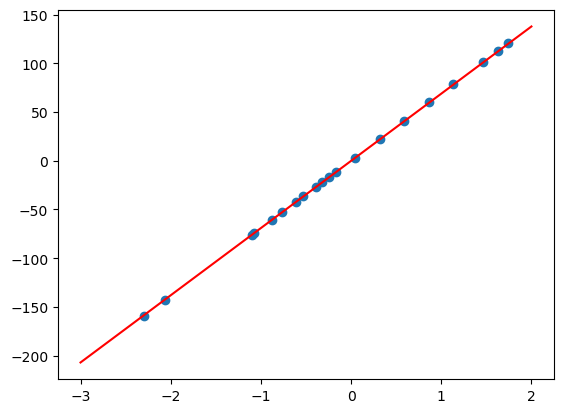

In [38]:
X0 = np.linspace(-3, 2, 100)
Y0 = hyp.predict(X0)
plt.figure()
plt.scatter(x, y)
plt.plot(X0, Y0, 'r')
plt.show()

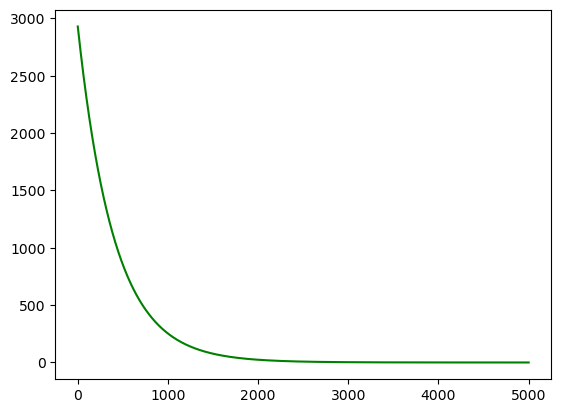

In [39]:
plt.figure()
plt.plot(steps, errors, 'g')
plt.show()